In [1]:
import numpy as np
import pandas as pd
from numpy import genfromtxt
from numba import njit
from tqdm import tqdm
import warnings
import networkx as nx


T = np.arange(0.001, 100, 1)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# Loading networks
cdata = genfromtxt("JCancer_483_0.09.csv",delimiter=',')
ndata = genfromtxt("JNormal_483_0.09.csv",delimiter=',')
# making edge lists
G1 = nx.Graph(cdata)
G2 = nx.Graph(ndata)

list_edges_cancer = np.asarray(list(G1.edges()), dtype=np.int64)
list_edges_normal = np.asarray(list(G2.edges()), dtype=np.int64)



# edges, common neighbors and triangles


def prepare_network(network, list_edges):

    n = len(network)

    # Existing neighbors of each node
    neighbors = [set(np.flatnonzero(network[i] != 0).tolist()) - {i} for i in range(n)]

    # Common neighbors for each edge
    common_flat = []
    offsets = [0]

    for i, j in list_edges:
        common = sorted(neighbors[i].intersection(neighbors[j]))
        common_flat.extend(common)
        offsets.append(len(common_flat))

    common_flat = np.asarray(common_flat, dtype=np.int64)
    offsets = np.asarray(offsets, dtype=np.int64)

    
    triangles = []

    for i in range(n):
        for j in neighbors[i]:
            if j > i:
                common = neighbors[i].intersection(neighbors[j])

                for k in common:
                    if k > j:
                        triangles.append((i, j, k))

    triangles = np.asarray(triangles, dtype=np.int64).reshape(-1, 3)

    
    denominator = 0.0

    for i, j, k in triangles:
        denominator += abs(network[i, j] * network[j, k] * network[k, i])

    return offsets, common_flat, triangles, denominator



# Energy 


@njit
def Energy(network, triangles, denominator):

    if denominator == 0:
        return np.nan

    weight = 0.0

    for q in range(len(triangles)):
        i = triangles[q, 0]
        j = triangles[q, 1]
        k = triangles[q, 2]

        weight += (network[i, j]* network[j, k]* network[k, i])

    return -weight / denominator

@njit
def Q(network): # mean of two stars
    q = 0
    w = 0 #weight
    for i in range(len(network)):
        for j in range(len(network)):
            for k in range(len(network)):
                if i>j>k:
                    q += network[i,k] * network[k,j]
                    w += np.abs(network[i,k]) * np.abs(network[k,j])
    return q/w


In [2]:

# Monte Carlo simulation compiled with Numba


@njit
def run_one_ensemble(Network,list_edges,offsets,common_flat,triangles,denominator,T):

    
    network = Network.copy()

    mncs = len(list_edges)
    energy_ens = np.empty(len(T))
    Q_ens = np.empty(len(T))
    

    for t_idx in range(len(T)):

        t = T[t_idx]

    
        for step in range(50 * mncs):

            # random picking an edge uniformly
            edge_idx = np.random.randint(0, mncs)

            i = list_edges[edge_idx, 0]
            j = list_edges[edge_idx, 1]

            # Calculate the energy after changing the sign of triangles
            s = 0.0

            for p in range(offsets[edge_idx],offsets[edge_idx + 1]):

                k = common_flat[p]
                s += network[j, k] * network[k, i]

            delta_E = (2.0 * s * network[i, j])

            # Metropolis acceptance rule
            if delta_E <= 0.0:
                network[i, j] *= -1
                network[j, i] *= -1

            elif np.random.random() < np.exp(-delta_E / t):
                network[i, j] *= -1
                network[j, i] *= -1

        # Record energy at the end of this temperature
        energy_ens[t_idx] = Energy(network, triangles, denominator)
        Q_ens[t_idx] = Q(network)
        

    return energy_ens, Q_ens



# Run independent ensembles


def monte_carlo_simulation(Network, mncs, ens_num, list_edges):

    list_edges = np.asarray(list_edges, dtype=np.int64)
    mncs = len(list_edges)

    offsets, common_flat, triangles, denominator = (prepare_network(Network, list_edges))

    e_ensemble = []
    q_ensemble = []
    

    for ens in tqdm(range(ens_num)):

        energy_ens, Q_ens = run_one_ensemble(Network,list_edges,offsets,common_flat,triangles,denominator,T)

        e_ensemble.append(energy_ens)
        q_ensemble.append(Q_ens)
        


    e_ensemble = np.asarray(e_ensemble)
    q_ensemble = np.asarray(q_ensemble)
    

    energy = np.mean(e_ensemble, axis=0)
    q = np.mean(q_ensemble, axis=0)
    variance = np.var(e_ensemble, axis=0)
    
    return T, energy, e_ensemble,q, variance



In [3]:
#modelling networks


Temp, cenergy, censemble,cq, cancer_variance = (monte_carlo_simulation(cdata, len(list_edges_cancer), 30, list_edges_cancer))

Temp, nenergy, nensemble,nq, normal_variance = (monte_carlo_simulation(ndata, len(list_edges_normal), 30, list_edges_normal))




100%|██████████| 30/30 [04:07<00:00,  8.24s/it]


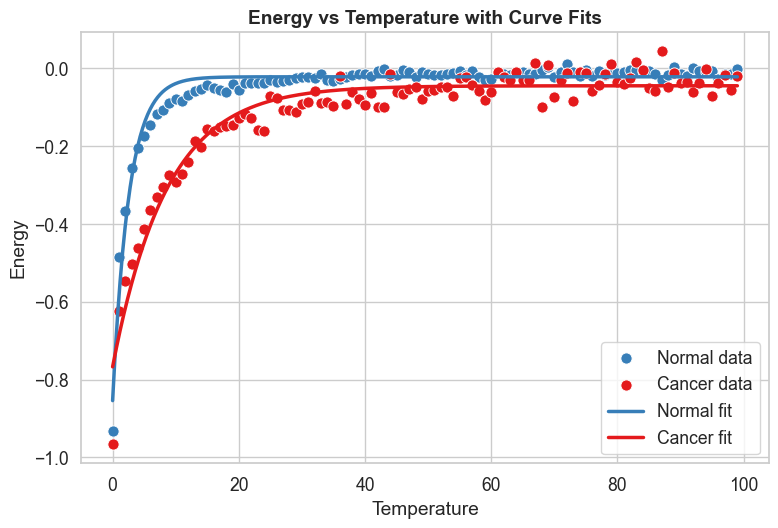

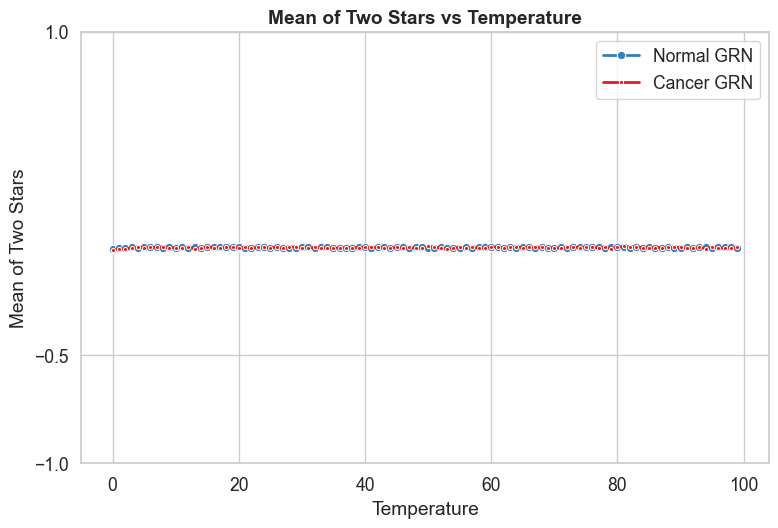

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.15)

normal_color = "#377eb8"
cancer_color = "#e41a1c"


#Fit energy curves
x = np.asarray(Temp)
yn = np.asarray(nenergy)
yc = np.asarray(cenergy)

def model(x, a, b, c):
    return c + a * (1 - np.exp(-b * x))

np0 = (max(yn) - min(yn), 0.3, min(yn))
cp0 = (max(yc) - min(yc), 0.3, min(yc))

nparams, ncovariance = curve_fit(model, x, yn, p0=np0, maxfev=10000)
cparams, ccovariance = curve_fit( model, x, yc, p0=cp0, maxfev=10000)

x_fit = np.linspace(x.min(), x.max(), 500)
yn_fit = model(x_fit, *nparams)
yc_fit = model(x_fit, *cparams)


# Experimental data and fitted curves
fig, ax = plt.subplots(figsize=(8, 5.5))

sns.scatterplot(x=x, y=yn, color=normal_color,s=65, label="Normal data", ax=ax)

sns.scatterplot(x=x, y=yc, color=cancer_color,s=65, label="Cancer data", ax=ax)

sns.lineplot(x=x_fit, y=yn_fit, color=normal_color,linewidth=2.5, label="Normal fit", ax=ax)

sns.lineplot(x=x_fit, y=yc_fit, color=cancer_color,linewidth=2.5, label="Cancer fit", ax=ax)

ax.set_xlabel("Temperature")
ax.set_ylabel("Energy")
ax.set_title("Energy vs Temperature with Curve Fits",fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()


# Mean of two stars vs temperature
fig, ax = plt.subplots(figsize=(8, 5.5))

sns.lineplot(x=Temp, y=nq, color=normal_color,marker="o", markersize=6, linewidth=2,label="Normal GRN", ax=ax)

sns.lineplot(x=Temp, y=cq, color=cancer_color,marker=".", markersize=6, linewidth=2,label="Cancer GRN", ax=ax)

ax.set_xlabel("Temperature")
ax.set_ylabel("Mean of Two Stars")
ax.set_title("Mean of Two Stars vs Temperature", fontweight="bold")
ax.set_ylim(-1, 0)
ax.set_yticks([-1, -0.5, 1])
ax.legend()
plt.tight_layout()
plt.show()





